# Ga for tuning the h-p

In this notebook I will tune the learning rate (lr), the activation function (af) and the number and size of the layers of the NN together.

## Details 
The idea is combine the results of the previous notebook (each notebook tuned a single paramter). 
I chose an ES $ \lambda + \mu $ with tournament selection. 

## Evolutionary operators 
The crossover operator for the lr is the one that given two point $a$ and $b$, it returns a point $x \in [a,b]$.
The crossover operator in the af, it returns two offsprings, one with the the af of the parent 1, and the other with the af of the parent 2.
The crossover operator for the structure is the single point crossover with average and it returns two offsprings. 

The mutation for the lr, add a noise to the lr following a gaussian distribution with mean zero and standard deviation computedd using the data of all the selection of that generation. 
The mutation for the af is replacing the current af with a random af. Obviusly, this is done with a low probability. 
The mutation for the structure of the NN is done by adding some noise to he units of a layer. The noise follows a uniform distribution in an interval computed as the 30\% of the average of the selection. 


## The NN

In [1]:
# Libs

import torch # the main pytorch library
from torch import nn # the sub-library containing neural networks
from torch.utils.data import DataLoader, Subset # an object that generates batches of data for training/testing
from torchvision import datasets # popular datasets, architectures and common image transformations
from torchvision.transforms import ToTensor # an easy way to convert PIL images to Tensors

import numpy as np # NumPy, the python array library
import random # for generating random numbers
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader, random_split


# Set seeds

SEED = 0 # seed for reproducibility

random.seed(SEED) # set the seed for random numbers
np.random.seed(SEED) # set the seed for numpy arrays


# Download training data
# Build validation data
# Download test data

# Parameters
validation_ratio = 0.2

# Download training data from open datasets
training_data = datasets.FashionMNIST(
    root="data",  # data is downloaded to this folder
    train=True,  # this is the training data
    download=True,  # download if data is not found locally
    transform=ToTensor(),  # convert the image to a PyTorch tensor
)


# Split dataset into training and validation sets
# train and validation data
num_samples = len(training_data)
num_validation_samples = int(validation_ratio * num_samples)
num_training_samples = num_samples - num_validation_samples

# First num_training_samples are for training 
# Last num_validation_samples are for validation
train_data = Subset(training_data, range(num_training_samples))
validation_data = Subset(training_data, range(num_training_samples, num_samples))



# Download test data from open datasets
test_data = datasets.FashionMNIST(
    root="data",  # data is downloaded to this folder
    train=False,  # this is the test data
    download=True,  # download if data is not found locally
    transform=ToTensor(),  # convert the image to a PyTorch tensor
)


# Define data loader (specifing batch size)

batch_size = 64 # the size of input data took for one iteration

# Create data loaders.
# Create data loaders
train_dataloader = DataLoader(train_data, batch_size=batch_size)
validation_dataloader = DataLoader(validation_data, batch_size=batch_size)
test_dataloader = DataLoader(test_data, batch_size=batch_size)

# N is batch size; 
# C is number of channels;
# H is height of image; 
# W is width of image
for X, y in train_dataloader:
    print(f"Shape of X [N, C, H, W]: {X.shape}")
    print(f"Shape of y: {y.shape} {y.dtype}")
    break

for X, y in validation_dataloader:
    print(f"Shape of X [N, C, H, W]: {X.shape}")
    print(f"Shape of y: {y.shape} {y.dtype}")
    break

for X, y in test_dataloader:
    print(f"Shape of X [N, C, H, W]: {X.shape}")
    print(f"Shape of y: {y.shape} {y.dtype}")
    break


# Set the device 
device = ( # check if gpu is available
    "cuda"
    if torch.cuda.is_available() # use gpu
    else "mps" # use mps
    if torch.backends.mps.is_available() # use mps
    else "cpu" # use cpu
)
print(f"Using {device} device\n")

# A model in which you can specify: 
# the number of hidden units,
# the activation function,
# whether to initialize the weights or not

class flexible_NN_units(nn.Module): # define a neural network class
    def __init__(self, 
                 input_size = 28*28,
                 hidden_size1 = 512,
                 hidden_size2 = 512,
                 output_size = 10,
                 activation_function = nn.ReLU,
                 initialize_weights = False): # initialisation method
        super().__init__() # initialise the neural network
        self.flatten = nn.Flatten() # flatten (appiattire) the input image
        self.activation_function = activation_function()
        self.linear_relu_stack = nn.Sequential( # create a sequence of layers
            nn.Linear(input_size, hidden_size1), # linear layer from 28*28 to 512 (28*28 is the size of the input image, 512 is the size of the output tensor)
            self.activation_function,  # activation function
            nn.Linear(hidden_size1, hidden_size2), # linear layer from 512 to 512 (512 is the size of the input tensor, 512 is the size of the output tensor)
            self.activation_function, # activation function
            nn.Linear(hidden_size2, output_size) # linear layer from 512 to 10 (512 is the size of the input tensor, 10 is the size of the output tensor)
        )
        if initialize_weights:
            self._initialize_weights()

    def forward(self, x): # forward method
        x = self.flatten(x) # flatten the input image
        logits = self.linear_relu_stack(x) # pass the input image through the sequence of layers
        return logits # return the output tensor
    
    def _initialize_weights(self):
      for m in self.modules():
          if isinstance(m, nn.Linear):
              nn.init.xavier_uniform_(m.weight)
              nn.init.zeros_(m.bias)



# A model in which you can specify: 
# the number of hidden layers and units,
# the activation function,
# whether to initialize the weights or not


class flexible_NN_layers(nn.Module): # define a neural network class
    def __init__(self, 
                 input_size = 28*28,
                 hidden_sizes = [512,512],
                 output_size = 10,
                 activation_function = nn.ReLU,
                 initialize_weights = False): # initialisation method
        super().__init__() # initialise the neural network
        self.flatten = nn.Flatten() # flatten (appiattire) the input image
        self.activation_function = activation_function()

        # Create a list to hold the layers
        layers = []
        previous_size = input_size

        # Add hidden layers dynamically
        for hidden_size in hidden_sizes:
            layers.append(nn.Linear(previous_size, hidden_size))
            layers.append(self.activation_function)
            previous_size = hidden_size
        layers.append(nn.Linear(previous_size, output_size)) # Add the final output layer

        # Create a sequential container with the layers
        # You shoould pass a list of layers to the Sequential container, one by one. 
        # You can do this by using the * operator to unpack the list of layers
        # This is done to avoid of passing a list of layers to the Sequential container (that is not correct)
        self.linear_relu_stack = nn.Sequential(*layers)
      
        if initialize_weights:
            self._initialize_weights()

    def forward(self, x): # forward method
        x = self.flatten(x) # flatten the input image
        logits = self.linear_relu_stack(x) # pass the input image through the sequence of layers
        return logits # return the output tensor
    
    def _initialize_weights(self):
      for m in self.modules():
          if isinstance(m, nn.Linear):
              nn.init.xavier_uniform_(m.weight)
              nn.init.zeros_(m.bias)


# Train and test functions

def train(dataloader, model, loss_fn, optimizer): # create a training function
    size = len(dataloader.dataset) # get the size of the dataset
    model.train() # set the model to training mode
    train_loss = 0.0 # initialise the training loss
    for batch, (X, y) in enumerate(dataloader): # iterate over the data
        X, y = X.to(device), y.to(device) # send the input data to the device

        # Compute prediction error
        pred = model(X) # get the model's prediction
        loss = loss_fn(pred, y) # compute the loss (between the model's prediction and the actual value)

        # Backpropagation
        loss.backward() # backpropagate the loss
        optimizer.step() # adjust the model parameters
        optimizer.zero_grad() # reset the gradients

        train_loss += loss.item()

        if batch % 100 == 0:
            loss, current = loss.item(), (batch + 1) * len(X) # get the loss and the current batch
            print(f"loss: {loss:>7f}  [{current:>5d}/{size:>5d}]")
    
    train_loss /= len(dataloader)
    return train_loss




def test(dataloader, model, loss_fn): # create a test function
    size = len(dataloader.dataset)
    num_batches = len(dataloader) # get the number of batches
    model.eval() # set the model to evaluation mode (test correspondece of model.train())
    test_loss, correct = 0, 0 # initialise the test loss and the number of correct predictions
    with torch.no_grad(): # disable gradient calculation
        for X, y in dataloader: # iterate over the data
            X, y = X.to(device), y.to(device) # send the input data to the device
            pred = model(X) # get the model's prediction
            test_loss += loss_fn(pred, y).item() # compute the loss
            correct += (pred.argmax(1) == y).type(torch.float).sum().item() # compute the number of correct predictions
    test_loss /= num_batches # compute the average loss
    correct /= size # compute the accuracy
    print(f"Test Error: \n Accuracy: {(100*correct):>0.1f}%, Avg loss: {test_loss:>8f} \n")
    return test_loss, 100*correct



# All in one function

def train_and_test_model(epochs, model, loss_fn, optimizer, train_dataloader, test_dataloader):
    train_loss_history = []
    test_loss_history = []
    accuracy_history = []

    for t in range(epochs):
        print(f"Epoch {t+1}\n-------------------------------")
        train_loss = train(train_dataloader, model, loss_fn, optimizer)
        test_loss, accuracy = test(test_dataloader, model, loss_fn)

        train_loss_history.append(train_loss)
        test_loss_history.append(test_loss)
        accuracy_history.append(accuracy)

    print("Done!")
    return train_loss_history, test_loss_history, accuracy_history


Shape of X [N, C, H, W]: torch.Size([64, 1, 28, 28])
Shape of y: torch.Size([64]) torch.int64
Shape of X [N, C, H, W]: torch.Size([64, 1, 28, 28])
Shape of y: torch.Size([64]) torch.int64
Shape of X [N, C, H, W]: torch.Size([64, 1, 28, 28])
Shape of y: torch.Size([64]) torch.int64
Using cpu device



## Useful commands 


In [2]:
from tqdm.notebook import tqdm
import time as time
import sys # to stop the execution of the code

def display_progress_bar(estimated_time, num_updates):
    # Calculate the sleep interval between updates
    sleep_interval = estimated_time / num_updates

    # Display the progress bar
    with tqdm(total=num_updates) as pbar:
        for i in range(num_updates):
            time.sleep(sleep_interval)
            pbar.update(1)

# Display the progress bar
estimated_time = 3
num_updates = 300

display_progress_bar(estimated_time, num_updates)

# Code before the exit
#print("This will run")
#raise SystemExit("Stopping execution here.")
#print("This will not run")

  0%|          | 0/300 [00:00<?, ?it/s]

## The EA 

### Structures

In [3]:
class Individual:
    def __init__(self, structure_gene, af_gene, lr_gene, fitness=0.0):
        """
        Initialize an individual with a gene, solution, and fitness.
        
        Parameters:
        gene (float): The value in the space of the gene.
        solution (Any): The value in the space of the solution.
        fitness (float): The fitness value of the individual.
        """
        self.structure_gene = structure_gene
        self.af_gene = af_gene
        self.lr_gene = lr_gene

        self.structure_solution = self.from_structureGene_to_structureSolution(structure_gene)  
        self.af_solution = self.af_gene
        self.lr_solution = self.lr_gene

        self.fitness = 0.0
    
    def from_structureGene_to_structureSolution(self, structureGenotype):
        """
        Convert the gene to a solution.
        """
        # For all element in the list of the genes, the solution is the list of the integer raund of the gene
        return [round(g) for g in structureGenotype]
    
    def __repr__(self):
        return f"Individual: nn_gene = {self.structure_gene}, af = {self.af_gene}, lr = {self.lr_gene} | nn_sol = {self.structure_solution}, Fitness = {self.fitness}"

# Example usage:
ind = Individual([512, 512], nn.ReLU, 0.001)
print(ind)

Individual: nn_gene = [512, 512], af = <class 'torch.nn.modules.activation.ReLU'>, lr = 0.001 | nn_sol = [512, 512], Fitness = 0.0


### Initialization

In [4]:
def initialization(
        initial_population_size,
        number_of_layers_interval,
        number_of_units_interval,
        activation_functions,
        learning_rate_interval):
    
    structure_genes = []
    
    for _ in range(initial_population_size):
        num_layers = random.randint(number_of_layers_interval[0], number_of_layers_interval[1])
        structure_gene = [random.randint(number_of_units_interval[0], number_of_units_interval[1]) for _ in range(num_layers)]
        structure_genes.append(structure_gene)

    af_genes = [random.choice(activation_functions) for _ in range(initial_population_size)]

    lr_genes = [random.uniform(learning_rate_interval[0], learning_rate_interval[1]) for _ in range(initial_population_size)]
    
    individuals = [Individual(structure_gene, af_gene, lr_gene) for structure_gene, af_gene, lr_gene in zip(structure_genes, af_genes, lr_genes)]

    return individuals

# Example usage:False
#ind 
population_size = 5
number_of_layers_interval=[1, 5]
number_of_units_interval=[10, 600]
activation_functions=[nn.ReLU, nn.Sigmoid, nn.Tanh, nn.LeakyReLU, nn.ELU, nn.SELU]
learning_rate_interval=[0.0001, 0.01]

population = initialization(
    initial_population_size = population_size,
    number_of_layers_interval = number_of_layers_interval,
    number_of_units_interval = number_of_units_interval,
    activation_functions = activation_functions,
    learning_rate_interval = learning_rate_interval)

for individual in population:
    print(individual)

Individual: nn_gene = [440, 51, 275, 533], af = <class 'torch.nn.modules.activation.LeakyReLU'>, lr = 0.0032303473252637753 | nn_sol = [440, 51, 275, 533], Fitness = 0.0
Individual: nn_gene = [424, 320, 498, 376], af = <class 'torch.nn.modules.activation.ELU'>, lr = 0.006440191675266694 | nn_sol = [424, 320, 498, 376], Fitness = 0.0
Individual: nn_gene = [233, 526, 152, 298, 153], af = <class 'torch.nn.modules.activation.ReLU'>, lr = 0.002124329720209561 | nn_sol = [233, 526, 152, 298, 153], Fitness = 0.0
Individual: nn_gene = [266], af = <class 'torch.nn.modules.activation.Tanh'>, lr = 0.005569984393733717 | nn_sol = [266], Fitness = 0.0
Individual: nn_gene = [160, 327, 111, 85, 348], af = <class 'torch.nn.modules.activation.LeakyReLU'>, lr = 0.004482664255548777 | nn_sol = [160, 327, 111, 85, 348], Fitness = 0.0


### Fitness assessment

In [5]:
def fitness_evaluation(
        individual,
        training_data,
        validation_data,
        num_epochs_per_evaluation,
        #lr,
        input_size,
        #hidden_sizes,
        output_size,
        #activation_function,
        initialize_weights):

    # Set the values from individual 
    lr = individual.lr_solution
    hidden_sizes = individual.structure_solution # HERE MUST BE solution, not gene
    activation_function = individual.af_solution

    # Set the device
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    
    # Create a new model
    model = flexible_NN_layers(
        input_size=input_size,
        hidden_sizes=hidden_sizes, 
        output_size=output_size,
        activation_function=activation_function,
        initialize_weights=initialize_weights).to(device)
    
    # Define loss function
    loss_fn = nn.CrossEntropyLoss()
    
    # Create a new optimizer with the specified learning rate
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)    
    
    # Train the model for the specified number of epochs
    for _ in range(num_epochs_per_evaluation):
        model.train()
        for X, y in training_data:
            X, y = X.to(device), y.to(device)
            pred = model(X)
            loss = loss_fn(pred, y)
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()
    
    # Compute the validation loss
    model.eval()
    validation_loss = 0
    with torch.no_grad():
        for X, y in validation_data:
            X, y = X.to(device), y.to(device)
            pred = model(X)
            loss = loss_fn(pred, y)
            validation_loss += loss.item()
    
    # Average validation loss over all batches
    validation_loss /= len(validation_data)
    
    return validation_loss


# Example usage:
individual = population[0]
training_data = train_dataloader
validation_data = validation_dataloader
num_epochs_per_evaluation = 5
#lr 
input_size = 28*28
#hidden_sizes 
output_size = 10
#activation_function 
initialize_weights = False

fitness = fitness_evaluation(
    individual=individual,
    training_data=training_data,
    validation_data=validation_data,
    num_epochs_per_evaluation=num_epochs_per_evaluation,
    input_size=input_size,
    output_size=output_size,
    initialize_weights=initialize_weights)

print(f"\nIndividual: {individual}")
print(f"Fitness of individual: {fitness}")


Individual: Individual: nn_gene = [440, 51, 275, 533], af = <class 'torch.nn.modules.activation.LeakyReLU'>, lr = 0.0032303473252637753 | nn_sol = [440, 51, 275, 533], Fitness = 0.0
Fitness of individual: 0.9048258427609789


In [6]:
# The function returns hours, minutes, seconds, and the whole execution time in seconds
def algorithm_time_estimation(
        individual,
        training_data,
        validation_data,
        num_epochs_per_evaluation,
        #lr,
        input_size,
        #hidden_sizes,
        output_size,
        #activation_function,
        initialize_weights,
        max_fitness_evaluations):

    # Set the values from individual
    lr = individual.lr_solution
    hidden_sizes = individual.structure_solution # HERE MUST BE solution, not gene
    activation_function = individual.af_solution

    # Time estimation
    start_time = time.time()  # Start timing

    # Set the device
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    
    # Create a new model
    model = flexible_NN_layers(
        input_size=input_size,
        hidden_sizes=hidden_sizes,
        output_size=output_size,
        activation_function=activation_function,
        initialize_weights=initialize_weights).to(device)
    
    # Define loss function
    loss_fn = nn.CrossEntropyLoss()
    
    # Create a new optimizer with the specified learning rate
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
        
    # Train the model for the specified number of epochs
    for _ in tqdm(range(10)):
        time.sleep(0.1)
        model.train()
        for X, y in training_data:
            X, y = X.to(device), y.to(device)
            pred = model(X)
            loss = loss_fn(pred, y)
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()
    
    # Compute the validation loss
    model.eval()
    validation_loss = 0
    with torch.no_grad():
        for X, y in validation_data:
            X, y = X.to(device), y.to(device)
            pred = model(X)
            loss = loss_fn(pred, y)
            validation_loss += loss.item()
    
    # Average validation loss over all batches
    validation_loss /= len(validation_data)

    # Time estimation
    end_time = time.time()  # End timing
    execution_time = end_time - start_time  # Calculate execution time
    whole_execution_time_seconds = execution_time/10 * num_epochs_per_evaluation * max_fitness_evaluations  # Calculate whole execution time
    execution_time_minutes = int(whole_execution_time_seconds // 60)
    execution_time_remainder_seconds = whole_execution_time_seconds % 60

    if execution_time_minutes > 59:
        execution_time_hours = int(execution_time_minutes // 60)
        execution_time_remainder_minutes = execution_time_minutes % 60
        return execution_time_hours, execution_time_remainder_minutes, 0,  whole_execution_time_seconds

    return  0, execution_time_minutes, round(execution_time_remainder_seconds), whole_execution_time_seconds


# Example usage:
individual = population[0]
training_data = train_dataloader
validation_data = validation_dataloader
num_epochs_per_evaluation = 10 # try 20
#lr = 0.01
input_size = 28*28
#hidden_sizes = [512, 512]
output_size = 10
#activation_function 
initialize_weights = True
max_fitness_evaluations = 40 # try 300

hours, minutes, seconds, whole_amount_in_seconds = algorithm_time_estimation(
    individual=individual,
    training_data=training_data,
    validation_data=validation_data,
    num_epochs_per_evaluation=num_epochs_per_evaluation,
    #lr=lr,
    input_size=input_size,
    #hidden_sizes=hidden_sizes,
    output_size=output_size,
    #activation_function=activation_function,
    initialize_weights=initialize_weights,
    max_fitness_evaluations=max_fitness_evaluations)

print(f"Number of fitness evaluations: {max_fitness_evaluations}")
print(f"Number of epochs per evaluation: {num_epochs_per_evaluation}")
print(f"\nTime estimation: {hours} hours, {minutes} minutes, {seconds} seconds (total seconds {whole_amount_in_seconds})")


  0%|          | 0/10 [00:00<?, ?it/s]

Number of fitness evaluations: 40
Number of epochs per evaluation: 10

Time estimation: 0 hours, 25 minutes, 51 seconds (total seconds 1551.3018226623535)


I AM HERE

In [7]:
# Assess population
def evaluate_individuals(
        individuals,
        training_data,
        validation_data,
        num_epochs_per_evaluation,
        #lr,
        input_size,
        #hidden_sizes,
        output_size,
        #activation_function,
        initialize_weights):
    
    for individual in individuals:
        individual.fitness = fitness_evaluation(
            individual=individual,
            training_data=training_data,
            validation_data=validation_data,
            num_epochs_per_evaluation=num_epochs_per_evaluation,
            #lr=lr,
            input_size=input_size,
            #hidden_sizes=hidden_sizes,
            output_size=output_size,
            #activation_function=activation_function,
            initialize_weights=initialize_weights)
        
    

# Example usage:
#population: defined before 
training_data = train_dataloader
validation_data = validation_dataloader
num_epochs_per_evaluation = 1
#lr = 0.01
input_size = 28*28
#hidden_sizes = [512, 512]
output_size = 10
#activation_function = nn.ReLU
initialize_weights = False

evaluate_individuals(
    individuals=population,
    training_data=training_data,
    validation_data=validation_data,
    num_epochs_per_evaluation=num_epochs_per_evaluation,
    #lr=lr,
    input_size=input_size,
    #hidden_sizes=hidden_sizes,
    output_size=output_size,
    #activation_function=activation_function,
    initialize_weights=initialize_weights)

for individual in population:
    print(individual)

Individual: nn_gene = [440, 51, 275, 533], af = <class 'torch.nn.modules.activation.LeakyReLU'>, lr = 0.0032303473252637753 | nn_sol = [440, 51, 275, 533], Fitness = 2.2897233633284872
Individual: nn_gene = [424, 320, 498, 376], af = <class 'torch.nn.modules.activation.ELU'>, lr = 0.006440191675266694 | nn_sol = [424, 320, 498, 376], Fitness = 1.2331709443254675
Individual: nn_gene = [233, 526, 152, 298, 153], af = <class 'torch.nn.modules.activation.ReLU'>, lr = 0.002124329720209561 | nn_sol = [233, 526, 152, 298, 153], Fitness = 2.3018673239870275
Individual: nn_gene = [266], af = <class 'torch.nn.modules.activation.Tanh'>, lr = 0.005569984393733717 | nn_sol = [266], Fitness = 0.9342776562305207
Individual: nn_gene = [160, 327, 111, 85, 348], af = <class 'torch.nn.modules.activation.LeakyReLU'>, lr = 0.004482664255548777 | nn_sol = [160, 327, 111, 85, 348], Fitness = 2.299810848337539


### Selection

In [8]:
def find_best_individual(population, maximize):
    """
    Find the individual with the best fitness value in the population.
    
    Parameters:
    population (list): A list of Individual objects.
    
    Returns:
    Individual: The individual with the best fitness value.
    """
    if maximize:
        best_individual = max(population, key=lambda x: x.fitness)
    else:
        best_individual = min(population, key=lambda x: x.fitness)
    return best_individual

# Example usage:
#population: defined before
maximize = False

best_individual = find_best_individual(population = population, maximize = maximize)   
print(best_individual)

Individual: nn_gene = [266], af = <class 'torch.nn.modules.activation.Tanh'>, lr = 0.005569984393733717 | nn_sol = [266], Fitness = 0.9342776562305207


In [9]:
# Tournament selection
# number_of_selected: The number of individuals to be selected.
# percentage_of_population_size: The percentage of the population size to use for the tournament.
# heterogeneity = True: If True, the selected individuals must be unique.
def tournament_selection(population, number_of_selected, percentage_of_population_size, heterogeneity):
    selected_individuals = []
    tournament_size = max(1, int(len(population) * percentage_of_population_size))

    for _ in range(number_of_selected):
        if heterogeneity:
            # Ensure uniqueness
            best_individual = None
            while best_individual is None or best_individual in selected_individuals:
                # Randomly select individuals for the tournament
                tournament_individuals = random.sample(population, tournament_size)
                # Select the best individual from the tournament
                best_individual = min(tournament_individuals, key=lambda ind: ind.fitness)
        else:
            # Randomly select individuals for the tournament
            tournament_individuals = random.sample(population, tournament_size)
            # Select the best individual from the tournament
            best_individual = min(tournament_individuals, key=lambda ind: ind.fitness)

        selected_individuals.append(best_individual)

    return selected_individuals

# Example usage:
#population: defined before
number_of_selected = 4
percentage_of_population_size = 0.2 # 20% of the population size
heterogeneity = False

selected_individuals = tournament_selection(
    population = population,
    number_of_selected = number_of_selected,
    percentage_of_population_size = percentage_of_population_size,
    heterogeneity=heterogeneity)

print("\nPopulation:")
for individual in population:
    print(individual)

print("\nSelected individuals:")
for individual in selected_individuals:
    print(individual)


Population:
Individual: nn_gene = [440, 51, 275, 533], af = <class 'torch.nn.modules.activation.LeakyReLU'>, lr = 0.0032303473252637753 | nn_sol = [440, 51, 275, 533], Fitness = 2.2897233633284872
Individual: nn_gene = [424, 320, 498, 376], af = <class 'torch.nn.modules.activation.ELU'>, lr = 0.006440191675266694 | nn_sol = [424, 320, 498, 376], Fitness = 1.2331709443254675
Individual: nn_gene = [233, 526, 152, 298, 153], af = <class 'torch.nn.modules.activation.ReLU'>, lr = 0.002124329720209561 | nn_sol = [233, 526, 152, 298, 153], Fitness = 2.3018673239870275
Individual: nn_gene = [266], af = <class 'torch.nn.modules.activation.Tanh'>, lr = 0.005569984393733717 | nn_sol = [266], Fitness = 0.9342776562305207
Individual: nn_gene = [160, 327, 111, 85, 348], af = <class 'torch.nn.modules.activation.LeakyReLU'>, lr = 0.004482664255548777 | nn_sol = [160, 327, 111, 85, 348], Fitness = 2.299810848337539

Selected individuals:
Individual: nn_gene = [160, 327, 111, 85, 348], af = <class 'tor

### Evolutionary operators 

#### Crossover operators

In [10]:
def correct_layer_size(gene, lb, ub):
    if gene < lb or gene > ub:
        if gene < lb:
            gene = lb
        else:
            gene = ub
    return gene
    
# Example of usage 
gene = 1000
lb = 16
ub = np.inf

corrected_gene = correct_layer_size(gene = gene, lb = lb, ub = ub)

print(f"Range: [{lb}, {ub}]")
print(f"\nGene: {gene}, \nCorrected gene: {corrected_gene}")


Range: [16, inf]

Gene: 1000, 
Corrected gene: 1000


In [11]:
def correct_layers_size(genotype, lb, ub):
    corrected_genotype = [lb if gene < lb else ub if gene > ub else gene for gene in genotype]
    return corrected_genotype

# Example of usage
genotype = [0, 20, 150]
lb = 10
ub = 100

corrected_genotype = correct_layers_size(genotype = genotype, lb = lb, ub = ub)

print(f"Range: [{lb}, {ub}]")
print(f"\nGenotype: {genotype}, \nCorrected genotype: {corrected_genotype}")

Range: [10, 100]

Genotype: [0, 20, 150], 
Corrected genotype: [10, 20, 100]


In [12]:
# Description:
# aaa|aa 
# bbb|bb
# --> aaa|bb, bbb|aa
def structure_singlePointCX(parent1, parent2):
    gene1, gene2 = parent1.structure_gene, parent2.structure_gene
    af_gene1, af_gene2 = parent1.af_gene, parent2.af_gene
    lr_gene1, lr_gene2 = parent1.lr_gene, parent2.lr_gene
    if len(gene1) == 1 or len(gene2) == 1:
        return parent1, parent2  # No crossover if a parent has only one layer
    point = random.randint(1, min(len(gene1), len(gene2)) - 1)
    child_gene1 = gene1[:point] + gene2[point:]
    child_gene2 = gene2[:point] + gene1[point:]
    child1 = Individual(structure_gene=child_gene1, af_gene=af_gene1, lr_gene=lr_gene1)
    child2 = Individual(structure_gene=child_gene2, af_gene=af_gene2, lr_gene=lr_gene2)
    return child1, child2

# Exmaple usage
parent1 = population[0]
parent2 = population[2]
offspring1, offspring2 = structure_singlePointCX(parent1, parent2)

print(f"Parent 1: {parent1}")
print(f"Parent 2: {parent2}")
print(f"\nOffspring2 CX: {offspring1}")
print(f"Offspring1 CX: {offspring2}")

Parent 1: Individual: nn_gene = [440, 51, 275, 533], af = <class 'torch.nn.modules.activation.LeakyReLU'>, lr = 0.0032303473252637753 | nn_sol = [440, 51, 275, 533], Fitness = 2.2897233633284872
Parent 2: Individual: nn_gene = [233, 526, 152, 298, 153], af = <class 'torch.nn.modules.activation.ReLU'>, lr = 0.002124329720209561 | nn_sol = [233, 526, 152, 298, 153], Fitness = 2.3018673239870275

Offspring2 CX: Individual: nn_gene = [440, 526, 152, 298, 153], af = <class 'torch.nn.modules.activation.LeakyReLU'>, lr = 0.0032303473252637753 | nn_sol = [440, 526, 152, 298, 153], Fitness = 0.0
Offspring1 CX: Individual: nn_gene = [233, 51, 275, 533], af = <class 'torch.nn.modules.activation.ReLU'>, lr = 0.002124329720209561 | nn_sol = [233, 51, 275, 533], Fitness = 0.0


In [13]:
def structure_SPC_E(parent1, parent2):
    gene1, gene2 = parent1.structure_gene, parent2.structure_gene
    af_gene1, af_gene2 = parent1.af_gene, parent2.af_gene
    lr_gene1, lr_gene2 = parent1.lr_gene, parent2.lr_gene
    
    # Determine the fittest parent
    if parent1.fitness < parent2.fitness:
        fitter_parent = parent1
        other_parent = parent2
    else:
        fitter_parent = parent2
        other_parent = parent1

    if len(gene1) == 1 or len(gene2) == 1:
        return parent1, parent2  # No crossover if a parent has only one layer
    
    point = random.randint(1, min(len(gene1), len(gene2)) - 1)
    
    # Split genes at the crossover point
    first_part_fitter = fitter_parent.structure_gene[:point]
    second_part_fitter = fitter_parent.structure_gene[point:]
    
    first_part_other = other_parent.structure_gene[:point]
    second_part_other = other_parent.structure_gene[point:]
    
    # Compute averages for the second part of genes
    avg_second_part = [(a + b) / 2 for a, b in zip(second_part_fitter, second_part_other)]
    avg_first_part = [(a + b) / 2 for a, b in zip(first_part_fitter, first_part_other)]
    
    # Create new genes for the children
    child_gene1 = first_part_fitter + avg_second_part
    child_gene2 = avg_first_part + second_part_fitter
    
    # Create child individuals
    child1 = Individual(structure_gene=child_gene1, af_gene=af_gene1, lr_gene =lr_gene1)
    child2 = Individual(structure_gene=child_gene2, af_gene=af_gene2, lr_gene =lr_gene2)
    
    return child1, child2

# Example usage
parent1 = population[0]
parent2 = population[2]
offspring1, offspring2 = structure_SPC_E(parent1, parent2)

print(f"Parent 1: {parent1}")
print(f"Parent 2: {parent2}")
print(f"\nOffspring1: {offspring1}")
print(f"Offspring2: {offspring2}")

Parent 1: Individual: nn_gene = [440, 51, 275, 533], af = <class 'torch.nn.modules.activation.LeakyReLU'>, lr = 0.0032303473252637753 | nn_sol = [440, 51, 275, 533], Fitness = 2.2897233633284872
Parent 2: Individual: nn_gene = [233, 526, 152, 298, 153], af = <class 'torch.nn.modules.activation.ReLU'>, lr = 0.002124329720209561 | nn_sol = [233, 526, 152, 298, 153], Fitness = 2.3018673239870275

Offspring1: Individual: nn_gene = [440, 288.5, 213.5, 415.5], af = <class 'torch.nn.modules.activation.LeakyReLU'>, lr = 0.0032303473252637753 | nn_sol = [440, 288, 214, 416], Fitness = 0.0
Offspring2: Individual: nn_gene = [336.5, 51, 275, 533], af = <class 'torch.nn.modules.activation.ReLU'>, lr = 0.002124329720209561 | nn_sol = [336, 51, 275, 533], Fitness = 0.0


In [14]:
# k = 0.5 is good, k = 0 is intermediate recombination 
def structure_SPC_lineRecombination(parent1, parent2, k, lb, ub):
    gene1, gene2 = parent1.structure_gene, parent2.structure_gene
    af_gene1, af_gene2 = parent1.af_gene, parent2.af_gene
    lr_gene1, lr_gene2 = parent1.lr_gene, parent2.lr_gene
    
    # Determine the fittest parent
    if parent1.fitness < parent2.fitness:
        fitter_parent = parent1
        other_parent = parent2
    else:
        fitter_parent = parent2
        other_parent = parent1

    if len(gene1) == 1 or len(gene2) == 1:
        return parent1, parent2  # No crossover if a parent has only one layer
    
    point = random.randint(1, min(len(gene1), len(gene2)) - 1)
    
    # Split genes at the crossover point
    first_part_fitter = fitter_parent.structure_gene[:point]
    second_part_fitter = fitter_parent.structure_gene[point:]
    
    first_part_other = other_parent.structure_gene[:point]
    second_part_other = other_parent.structure_gene[point:]
    
    # Compute averages for the second part of genes

    max_len_first_part = max(len(first_part_fitter), len(first_part_other))
    max_len_second_part = max(len(second_part_fitter), len(second_part_other))
    ks_first_part =  [random.uniform(-k, 1 + k) for _ in range(max_len_first_part)]
    ks_second_part =  [random.uniform(-k, 1 + k) for _ in range(max_len_second_part)]
    
    line_recombination_first_part = [
        kk * a + (1 - kk) * b
        for a, b, kk in zip(first_part_other, first_part_fitter, ks_first_part)]
    line_recombination_second_part = [
        kk * a + (1 - kk) * b
        for a, b, kk in zip(second_part_other, second_part_fitter, ks_second_part)]
    
    
    # Create new genes for the children
    child_gene1 = first_part_fitter + line_recombination_second_part
    child_gene2 = line_recombination_first_part + second_part_fitter

    child_gene1 = correct_layers_size(genotype=child_gene1, lb=lb, ub=ub)
    child_gene2 = correct_layers_size(genotype=child_gene2, lb=lb, ub=ub)
    
    # Create child individuals
    child1 = Individual(structure_gene=child_gene1, af_gene=af_gene1, lr_gene =lr_gene1)
    child2 = Individual(structure_gene=child_gene2, af_gene=af_gene2, lr_gene =lr_gene2)
    
    return child1, child2

# Example usage
parent1 = population[0]
parent2 = population[2]
k = 0
lb = 16
ub = np.inf
offspring1, offspring2 = structure_SPC_lineRecombination(parent1 = parent1, parent2 = parent2, k = k, lb = lb, ub = ub )


print(f"Parent 1: {parent1}")
print(f"Parent 2: {parent2}")
print(f"\nOffspring1: {offspring1}")
print(f"Offspring2: {offspring2}")

Parent 1: Individual: nn_gene = [440, 51, 275, 533], af = <class 'torch.nn.modules.activation.LeakyReLU'>, lr = 0.0032303473252637753 | nn_sol = [440, 51, 275, 533], Fitness = 2.2897233633284872
Parent 2: Individual: nn_gene = [233, 526, 152, 298, 153], af = <class 'torch.nn.modules.activation.ReLU'>, lr = 0.002124329720209561 | nn_sol = [233, 526, 152, 298, 153], Fitness = 2.3018673239870275

Offspring1: Individual: nn_gene = [440, 51, 275, 386.0625301206964], af = <class 'torch.nn.modules.activation.LeakyReLU'>, lr = 0.0032303473252637753 | nn_sol = [440, 51, 275, 386], Fitness = 0.0
Offspring2: Individual: nn_gene = [266.1011181730295, 388.3703762278062, 178.43912556631236, 533], af = <class 'torch.nn.modules.activation.ReLU'>, lr = 0.002124329720209561 | nn_sol = [266, 388, 178, 533], Fitness = 0.0


In [15]:
def af_crossover(parent1, parent2, p_pick_the_best):

    # Find the af of the fittest parent
    if parent1.fitness < parent2.fitness:
        af1 = parent1.af_gene # af of the fittest parent
        af2 = parent2.af_gene
    else:
        af1 = parent2.af_gene
        af2 = parent1.af_gene

    # Define two individuals with a probability p to pick the af of the fittest parent
    if random.random() < p_pick_the_best:
        child1 = Individual(structure_gene=parent1.structure_gene, af_gene=af1, lr_gene=parent1.lr_gene)
        child2 = Individual(structure_gene=parent2.structure_gene, af_gene=af1, lr_gene=parent2.lr_gene)
    else:
        child1 = Individual(structure_gene=parent1.structure_gene, af_gene=af2, lr_gene=parent1.lr_gene)
        child2 = Individual(structure_gene=parent2.structure_gene, af_gene=af2, lr_gene=parent2.lr_gene)
    
    return child1, child2

# Example usage
parent1 = population[0]
parent2 = population[1]

p_pick_the_best = 0.5

offspring1, offspring2 = af_crossover(parent1, parent2, p_pick_the_best)

print(f"Parent 1: {parent1}")
print(f"Parent 2: {parent2}")
print(f"\nOffspring1: {offspring1}")
print(f"Offspring2: {offspring2}")



Parent 1: Individual: nn_gene = [440, 51, 275, 533], af = <class 'torch.nn.modules.activation.LeakyReLU'>, lr = 0.0032303473252637753 | nn_sol = [440, 51, 275, 533], Fitness = 2.2897233633284872
Parent 2: Individual: nn_gene = [424, 320, 498, 376], af = <class 'torch.nn.modules.activation.ELU'>, lr = 0.006440191675266694 | nn_sol = [424, 320, 498, 376], Fitness = 1.2331709443254675

Offspring1: Individual: nn_gene = [440, 51, 275, 533], af = <class 'torch.nn.modules.activation.LeakyReLU'>, lr = 0.0032303473252637753 | nn_sol = [440, 51, 275, 533], Fitness = 0.0
Offspring2: Individual: nn_gene = [424, 320, 498, 376], af = <class 'torch.nn.modules.activation.LeakyReLU'>, lr = 0.006440191675266694 | nn_sol = [424, 320, 498, 376], Fitness = 0.0


In [16]:
def lr_linearRecombination(parent1, parent2, k):

    gene1 = parent1.lr_gene
    gene2 = parent2.lr_gene
    a1 = np.random.uniform(-k, 1 + k)
    a2 = np.random.uniform(-k, 1 + k)

    child_gene1 = a1 * gene1 + (1 - a1) * gene2
    child_gene2 = a2 * gene1 + (1 - a2) * gene2    

    child1 = Individual(structure_gene=parent1.structure_gene, af_gene=parent1.af_gene, lr_gene=child_gene1)
    child2 = Individual(structure_gene=parent2.structure_gene, af_gene=parent2.af_gene, lr_gene=child_gene2)
                           
    return child1, child2

# Example usage:
parent1 = population[0]
parent2 = population[1]
k = 0

offspring1, offspring2 = lr_linearRecombination(parent1, parent2, k)

print(f"Parent 1: {parent1}")
print(f"Parent 2: {parent2}")
print(f"\nOffspring1: {offspring1}")
print(f"Offspring2: {offspring2}")


Parent 1: Individual: nn_gene = [440, 51, 275, 533], af = <class 'torch.nn.modules.activation.LeakyReLU'>, lr = 0.0032303473252637753 | nn_sol = [440, 51, 275, 533], Fitness = 2.2897233633284872
Parent 2: Individual: nn_gene = [424, 320, 498, 376], af = <class 'torch.nn.modules.activation.ELU'>, lr = 0.006440191675266694 | nn_sol = [424, 320, 498, 376], Fitness = 1.2331709443254675

Offspring1: Individual: nn_gene = [440, 51, 275, 533], af = <class 'torch.nn.modules.activation.LeakyReLU'>, lr = 0.0046785857504802655 | nn_sol = [440, 51, 275, 533], Fitness = 0.0
Offspring2: Individual: nn_gene = [424, 320, 498, 376], af = <class 'torch.nn.modules.activation.ELU'>, lr = 0.0041445451284340155 | nn_sol = [424, 320, 498, 376], Fitness = 0.0


#### Mutation operators

In [17]:
def structure_PP_selfAdaptiveMutation(population):
    # Find the maximum lenght of the genes of the population 
    max_len = max([len(ind.structure_gene) for ind in population])

    # Find the mean of each gene of the genotype
    genotype_mean = [np.mean([ind.structure_gene[i] for ind in population if i < len(ind.structure_gene)]) for i in range(max_len)]

    # Find the maximum of each gene of the genotype
    genotype_max = [np.max([ind.structure_gene[i] for ind in population if i < len(ind.structure_gene)]) for i in range(max_len)]

    return genotype_mean, genotype_max

# Example usage
#population: defined before
genotype_mean, genotype_max = structure_PP_selfAdaptiveMutation(population)

print("Population:")
for individual in population:
    print(individual)

print("\nGenotype mean:")
print(genotype_mean)    

print("\nGenotype max:")
print(genotype_max)    


Population:
Individual: nn_gene = [440, 51, 275, 533], af = <class 'torch.nn.modules.activation.LeakyReLU'>, lr = 0.0032303473252637753 | nn_sol = [440, 51, 275, 533], Fitness = 2.2897233633284872
Individual: nn_gene = [424, 320, 498, 376], af = <class 'torch.nn.modules.activation.ELU'>, lr = 0.006440191675266694 | nn_sol = [424, 320, 498, 376], Fitness = 1.2331709443254675
Individual: nn_gene = [233, 526, 152, 298, 153], af = <class 'torch.nn.modules.activation.ReLU'>, lr = 0.002124329720209561 | nn_sol = [233, 526, 152, 298, 153], Fitness = 2.3018673239870275
Individual: nn_gene = [266], af = <class 'torch.nn.modules.activation.Tanh'>, lr = 0.005569984393733717 | nn_sol = [266], Fitness = 0.9342776562305207
Individual: nn_gene = [160, 327, 111, 85, 348], af = <class 'torch.nn.modules.activation.LeakyReLU'>, lr = 0.004482664255548777 | nn_sol = [160, 327, 111, 85, 348], Fitness = 2.299810848337539

Genotype mean:
[304.6, 306.0, 259.0, 323.0, 250.5]

Genotype max:
[440, 526, 498, 533, 

In [37]:
def structure_selfAdaptiveGaussianMutation(parent, genotype_mean, lb, ub):
    gene = parent.structure_gene
    mutated_gene = []
    for i in range(len(gene)):
        mutated_gene.append(gene[i] + np.random.normal(0, genotype_mean[i]/10))
        mutated_gene[i] = correct_layer_size(gene=mutated_gene[i], lb=lb, ub=ub)
    return Individual(structure_gene=mutated_gene, af_gene=parent.af_gene, lr_gene=parent.lr_gene)  
    
# Example usage
parent = population[0]
#genotype_mean: defined before
lb = 16
ub = np.inf

mutated_individual = structure_selfAdaptiveGaussianMutation(parent=parent, genotype_mean=genotype_mean, lb=lb, ub=ub)

print(f"Gentype mean: {genotype_mean}\n")

for g1, g2 in zip(parent.structure_gene, mutated_individual.structure_gene):
    print(f"Gene: {g1} -> {g2}")


Gentype mean: [304.6, 306.0, 259.0, 323.0, 250.5]

Gene: 440 -> 441.3938044370021
Gene: 51 -> 45.272174189209494
Gene: 275 -> 314.698981651884
Gene: 533 -> 580.4602882677792


In [38]:
def af_mutation(parent, activation_functions, p_change_af):
    gene = parent.af_gene
    if random.random() < p_change_af:
        gene = random.choice(activation_functions)
    return Individual(structure_gene=parent.structure_gene, af_gene=gene, lr_gene=parent.lr_gene)

# Example usage
parent = population[0]
activation_functions = [nn.ReLU, nn.Sigmoid, nn.Tanh, nn.LeakyReLU, nn.ELU, nn.SELU]
p_change_af = 0.5

mutated_individual = af_mutation(parent=parent, activation_functions=activation_functions, p_change_af=p_change_af)

print(f"Parent: {parent}")
print(f"Mutated individual: {mutated_individual}")

Parent: Individual: nn_gene = [440, 51, 275, 533], af = <class 'torch.nn.modules.activation.LeakyReLU'>, lr = 0.0032303473252637753 | nn_sol = [440, 51, 275, 533], Fitness = 2.2897233633284872
Mutated individual: Individual: nn_gene = [440, 51, 275, 533], af = <class 'torch.nn.modules.activation.LeakyReLU'>, lr = 0.0032303473252637753 | nn_sol = [440, 51, 275, 533], Fitness = 0.0


In [39]:
def lr_PP_selfAdaptiveMutation(population):
    # Find the mean of the learning rates of the population
    lr_mean = np.mean([ind.lr_gene for ind in population])
    return lr_mean

# Example usage
#population: defined before

lr_mean = lr_PP_selfAdaptiveMutation(population)

print("Population:")
for individual in population:
    print(individual)

print(f"\nLearning rate mean: {lr_mean}")


Population:
Individual: nn_gene = [440, 51, 275, 533], af = <class 'torch.nn.modules.activation.LeakyReLU'>, lr = 0.0032303473252637753 | nn_sol = [440, 51, 275, 533], Fitness = 2.2897233633284872
Individual: nn_gene = [424, 320, 498, 376], af = <class 'torch.nn.modules.activation.ELU'>, lr = 0.006440191675266694 | nn_sol = [424, 320, 498, 376], Fitness = 1.2331709443254675
Individual: nn_gene = [233, 526, 152, 298, 153], af = <class 'torch.nn.modules.activation.ReLU'>, lr = 0.002124329720209561 | nn_sol = [233, 526, 152, 298, 153], Fitness = 2.3018673239870275
Individual: nn_gene = [266], af = <class 'torch.nn.modules.activation.Tanh'>, lr = 0.005569984393733717 | nn_sol = [266], Fitness = 0.9342776562305207
Individual: nn_gene = [160, 327, 111, 85, 348], af = <class 'torch.nn.modules.activation.LeakyReLU'>, lr = 0.004482664255548777 | nn_sol = [160, 327, 111, 85, 348], Fitness = 2.299810848337539

Learning rate mean: 0.004369503474004504


In [40]:
def correct_lr(gene, lb, ub):
    if gene < lb or gene > ub:
        if gene < lb:
            gene = lb
        else:
            gene = ub
    return gene

In [41]:
def lr_selfAdaptiveGaussianMutation(parent, lr_mean, lb, ub):
    gene = parent.lr_gene
    mutated_gene = gene + np.random.normal(0, lr_mean/10)
    mutated_gene = correct_lr(gene=mutated_gene, lb=lb, ub=ub)
    return Individual(structure_gene=parent.structure_gene, af_gene=parent.af_gene, lr_gene=mutated_gene)

# Example usage
parent = population[0]
#lr_mean: defined before
lb = 0.0001
ub = 0.01

mutated_individual = lr_selfAdaptiveGaussianMutation(parent=parent, lr_mean=lr_mean, lb=lb, ub=ub)

print(f"Parent: {parent}")
print(f"Mutated individual: {mutated_individual}")


Parent: Individual: nn_gene = [440, 51, 275, 533], af = <class 'torch.nn.modules.activation.LeakyReLU'>, lr = 0.0032303473252637753 | nn_sol = [440, 51, 275, 533], Fitness = 2.2897233633284872
Mutated individual: Individual: nn_gene = [440, 51, 275, 533], af = <class 'torch.nn.modules.activation.LeakyReLU'>, lr = 0.0032980516567508483 | nn_sol = [440, 51, 275, 533], Fitness = 0.0


In [42]:
# This mutation removes a gene
def structure_shrink_mutation(individual):
    mutated_gene = individual.structure_gene.copy()
    if len(mutated_gene) <= 1:
        return Individual(structure_gene=mutated_gene, af_gene=individual.af_gene, lr_gene=individual.lr_gene)
    
    index = random.randint(0, len(mutated_gene) - 1)
    mutated_gene.pop(index)
    
    return Individual(structure_gene=mutated_gene, af_gene=individual.af_gene, lr_gene=individual.lr_gene)  

# Example usage
individual = population[0]
mutated_individual = structure_shrink_mutation(individual)

print(f"Individual: {individual}")
print(f"Mutated individual: {mutated_individual}")

Individual: Individual: nn_gene = [440, 51, 275, 533], af = <class 'torch.nn.modules.activation.LeakyReLU'>, lr = 0.0032303473252637753 | nn_sol = [440, 51, 275, 533], Fitness = 2.2897233633284872
Mutated individual: Individual: nn_gene = [440, 51, 275], af = <class 'torch.nn.modules.activation.LeakyReLU'>, lr = 0.0032303473252637753 | nn_sol = [440, 51, 275], Fitness = 0.0


In [43]:
# This mutation adds a gene
def structure_gaussianGrowMutation(individual, genotype_mean, position, lb, ub):
    mutated_gene = individual.structure_gene.copy()
    
    # Determine the index to insert the new gene 
    if position == 'beginning':
        index = 0
    elif position == 'end':
        index = len(mutated_gene)
    else:  # Default to inserting at a random position
        index = random.randint(0, len(mutated_gene))

    # If condition 
    # It can happen that the new layer is the last one AND the largest individual has less number of layer 
    # So, we don't have data on the average of the population for that position  
    if index == len(mutated_gene) and len(mutated_gene) >= len(genotype_mean):
        inspiration_index = random.randint(0, len(genotype_mean) - 1) # Randomly select an index from the genotype
        new_layer_size = np.random.normal(genotype_mean[inspiration_index], genotype_mean[inspiration_index]/10)
        new_layer_size = correct_layer_size(gene=new_layer_size, lb=lb, ub=ub)
        mutated_gene.insert(index, new_layer_size)
    else:
        new_layer_size = np.random.normal(genotype_mean[index], genotype_mean[index]/10)
        new_layer_size = correct_layer_size(gene=new_layer_size, lb=lb, ub=ub)
        mutated_gene.insert(index, new_layer_size)
    
    return Individual(structure_gene=mutated_gene, af_gene=individual.af_gene, lr_gene=individual.lr_gene)

# Example usage
individual = population[0]
#genotype_max: defined before
#genotype_mean: defined before
position = 'random'
lb = 16
ub = np.inf

mutated_individual = structure_gaussianGrowMutation(individual=individual, genotype_mean=genotype_mean, position=position, lb=lb, ub=ub)

print(f"Genotype mean: {genotype_mean}\n")

print(f"Individual: {individual}")
print(f"Mutated individual: {mutated_individual}")



Genotype mean: [304.6, 306.0, 259.0, 323.0, 250.5]

Individual: Individual: nn_gene = [440, 51, 275, 533], af = <class 'torch.nn.modules.activation.LeakyReLU'>, lr = 0.0032303473252637753 | nn_sol = [440, 51, 275, 533], Fitness = 2.2897233633284872
Mutated individual: Individual: nn_gene = [440, 51, 275, 533, 259.97297111603444], af = <class 'torch.nn.modules.activation.LeakyReLU'>, lr = 0.0032303473252637753 | nn_sol = [440, 51, 275, 533, 260], Fitness = 0.0


### Update population

In [44]:
def generate_offsprings(
        population,
        number_of_offsprings,
        tournament_percentage,
        p_crossover_vs_mutation,
        structure_k_crossover,
        structure_lb_size,
        structure_ub_size,
        af_p_pick_the_best,
        lr_k,
        p_changeLength_mutation,
        structure_grow_position,
        activation_functions,
        af_p_change_af,
        lr_lb,
        lr_ub):
    
    offsprings = []

    # Pre-process the population
    structure_genotype_mean, _ = structure_PP_selfAdaptiveMutation(population=population)
    lr_genotype_mean = lr_PP_selfAdaptiveMutation(population=population)

    

    for _ in range(number_of_offsprings // 2):
        # Select parents for crossover
        parent1, parent2 = tournament_selection(population = population, number_of_selected=2, percentage_of_population_size=tournament_percentage, heterogeneity=False)

        if random.random() < p_crossover_vs_mutation:
            offspring1, offspring2 = structure_SPC_lineRecombination(parent1 = parent1, parent2 = parent2, k = structure_k_crossover, lb = structure_lb_size, ub = structure_ub_size)
            offspring1, offspring2 = af_crossover(parent1=offspring1, parent2=offspring2, p_pick_the_best=af_p_pick_the_best)
            offspring1, offspring2 = lr_linearRecombination(parent1=offspring1, parent2=offspring2, k = lr_k)
        else:
            if random.random() < p_changeLength_mutation:
                offspring1 = structure_shrink_mutation(individual = parent1)
                offspring2 = structure_gaussianGrowMutation(individual = parent2, genotype_mean = structure_genotype_mean, position = structure_grow_position, lb = structure_lb_size, ub = structure_lb_size)

                offspring1 = af_mutation(parent=offspring1, activation_functions=activation_functions, p_change_af= af_p_change_af)
                offspring2 = af_mutation(parent=offspring2, activation_functions=activation_functions, p_change_af= af_p_change_af)

                offspring1 = lr_selfAdaptiveGaussianMutation(parent = offspring1, lr_mean = lr_genotype_mean, lb = lr_lb, ub =lr_ub)
                offspring2 = lr_selfAdaptiveGaussianMutation(parent = offspring2, lr_mean = lr_genotype_mean, lb = lr_lb, ub =lr_ub)
            else: 
                offspring1 = structure_selfAdaptiveGaussianMutation(parent = parent1, genotype_mean=structure_genotype_mean, lb = structure_lb_size, ub = structure_ub_size)
                offspring2 = structure_selfAdaptiveGaussianMutation(parent = parent2, genotype_mean=structure_genotype_mean, lb = structure_lb_size, ub = structure_ub_size)

                offspring1 = af_mutation(parent=offspring1, activation_functions=activation_functions, p_change_af= af_p_change_af)
                offspring2 = af_mutation(parent=offspring2, activation_functions=activation_functions, p_change_af= af_p_change_af)

                offspring1 = lr_selfAdaptiveGaussianMutation(parent = offspring1, lr_mean = lr_genotype_mean, lb = lr_lb, ub =lr_ub)
                offspring2 = lr_selfAdaptiveGaussianMutation(parent = offspring2, lr_mean = lr_genotype_mean, lb = lr_lb, ub =lr_ub)

        # Add the offspring to the population
        offsprings.append(offspring1)
        offsprings.append(offspring2)
            
    # If it is odd
    if number_of_offsprings % 2 == 1:
        parent1 = tournament_selection(population = population, number_of_selected=1, percentage_of_population_size=tournament_percentage, heterogeneity=False)
        offspring1 = structure_selfAdaptiveGaussianMutation(parent = parent1, genotype_mean=structure_genotype_mean, lb = structure_lb_size, ub = structure_ub_size)
        offspring1 = af_mutation(parent=offspring1, activation_functions=activation_functions, p_change_af= af_p_change_af)
        offspring1 = lr_selfAdaptiveGaussianMutation(parent = offspring1, lr_mean = lr_genotype_mean, lb = lr_lb, ub =lr_ub)
        offsprings.append(offspring1)    

    return offsprings



# Example usage
#population: defined before
number_of_offsprings = 10
tournament_percentage = 0.2
p_crossover_vs_mutation = 0.5
structure_k_crossover = 0.5
structure_lb_size = 10
structure_ub_size = 600
af_p_pick_the_best = 0.75
lr_k = 0
p_changeLength_mutation = 0.20
structure_grow_position = 'random'
activation_functions = [nn.ReLU, nn.LeakyReLU, nn.Tanh]
af_p_change_af = 0.2
lr_lb = 0.00001
lr_ub  = 0.1        
        
offsprings = generate_offsprings(
        population = population,
        number_of_offsprings = number_of_offsprings,
        tournament_percentage = tournament_percentage,
        p_crossover_vs_mutation = p_crossover_vs_mutation,
        structure_k_crossover = structure_k_crossover,
        structure_lb_size = structure_lb_size,
        structure_ub_size = structure_ub_size,
        af_p_pick_the_best = af_p_pick_the_best,
        lr_k = lr_k,
        p_changeLength_mutation = p_changeLength_mutation,
        structure_grow_position = structure_grow_position,
        activation_functions = activation_functions,
        af_p_change_af = af_p_change_af,
        lr_lb = lr_lb,
        lr_ub = lr_ub)



print("\nPopulation:")
for individual in population:
    print(individual)

print("\nOffsprings:")
for offspring in offsprings:
    print(offspring)
    
    


Population:
Individual: nn_gene = [440, 51, 275, 533], af = <class 'torch.nn.modules.activation.LeakyReLU'>, lr = 0.0032303473252637753 | nn_sol = [440, 51, 275, 533], Fitness = 2.2897233633284872
Individual: nn_gene = [424, 320, 498, 376], af = <class 'torch.nn.modules.activation.ELU'>, lr = 0.006440191675266694 | nn_sol = [424, 320, 498, 376], Fitness = 1.2331709443254675
Individual: nn_gene = [233, 526, 152, 298, 153], af = <class 'torch.nn.modules.activation.ReLU'>, lr = 0.002124329720209561 | nn_sol = [233, 526, 152, 298, 153], Fitness = 2.3018673239870275
Individual: nn_gene = [266], af = <class 'torch.nn.modules.activation.Tanh'>, lr = 0.005569984393733717 | nn_sol = [266], Fitness = 0.9342776562305207
Individual: nn_gene = [160, 327, 111, 85, 348], af = <class 'torch.nn.modules.activation.LeakyReLU'>, lr = 0.004482664255548777 | nn_sol = [160, 327, 111, 85, 348], Fitness = 2.299810848337539

Offsprings:
Individual: nn_gene = [233, 526, 152, 298, 153], af = <class 'torch.nn.mod

### Complete algorithm

In [115]:
# Ea for finding the best actiavtion function 

def es_lambda_plus_mu_for_size_and_units(
        max_fitness_evaluations, # 50 is suggested 
        beginning_population_size,
        offsprings_size,
        number_of_layers_interval,
        number_of_units_interval,
        percentage_of_population_size_for_tournament,
        crossover_operator,
        integer_mutation_probability_per_layer,
        percentage_of_integer_mutation,
        grow_shrink_mutation_operator_check,
        grow_shrink_mutation_probability,
        minimum_gene,
        maximum_gene,
        train_dataloader=train_dataloader,
        validation_dataloader=validation_dataloader,
        num_epochs_per_evaluation=5, # 10 is suggested 
        lr = 0.0096,
        input_size = 28*28,
        output_size = 10,
        activation_function = nn.LeakyReLU,
        initialize_weights = False
        ):
    
    # Initialize the population
    fitness_evaluations = 0
    gen_index = 1
    population = initialization(
        population_size = beginning_population_size,
        number_of_layers_interval = number_of_layers_interval,
        number_of_units_interval = number_of_units_interval)
    fitness_evaluations += beginning_population_size
    evaluate_population(
        population = population,
        training_data = train_dataloader,
        validation_data = validation_dataloader,
        num_epochs_per_evaluation=num_epochs_per_evaluation,
        lr = lr,
        input_size = input_size,
        output_size = output_size,
        activation_function = activation_function,
        initialize_weights = initialize_weights)
       
    best_individual = find_best_individual(population)
    # Print the status of the population
    print(f"\nGeneration: {gen_index} | Fitness evalutions: {fitness_evaluations} | Best individual: {best_individual}")
    for individual in population:
        print(individual)

    while fitness_evaluations < max_fitness_evaluations:
        # Select parents using tournament selection
        parents = tournament_selection(
            population = population,
            number_of_selected=offsprings_size, 
            percentage_of_population_size=percentage_of_population_size_for_tournament)
        # Create offsprings
        offsprings = create_offsprings(
            parents = parents,
            offsprings_size = offsprings_size,
            crossover_operator=crossover_operator,
            integer_mutation_probability_per_layer=integer_mutation_probability_per_layer,
            percentage_of_integer_mutation = percentage_of_integer_mutation,
            grow_shrink_mutation_operator_check=grow_shrink_mutation_operator_check,
            grow_shrink_mutation_probability=grow_shrink_mutation_probability,
            minimum_gene=minimum_gene,
            maximum_gene=maximum_gene)
        for offspring in offsprings:
            print(offspring)
        # Evaluate the new population
        evaluate_population(
            population = offsprings,
            training_data = train_dataloader,
            validation_data = validation_dataloader,
            num_epochs_per_evaluation=num_epochs_per_evaluation,
            lr = lr,
            input_size = input_size,
            output_size = output_size,
            activation_function=activation_function,
            initialize_weights = initialize_weights)
        for offspring in offsprings:
            population.append(offspring) # Add the offsprings to the population, one by one :)  
        fitness_evaluations += offsprings_size

        # Find the best individual in the new population
        best_individual = find_best_individual(population)
        print(f"\nGeneration: {gen_index + 1} | Fitness evalutions: {fitness_evaluations} | Best individual: {best_individual}")
        for individual in population:
            print(individual)
        gen_index += 1

    return best_individual

## IMP
The problem is that the best individual is every generation an individual with only one layer, and after the test, it is not the best structure of the dl.
Indeed, the structure [256,128,64,32] is better then [512,512] that is better then [512]. 
In my opinion, there are two possible reasons why the ES prefers individual with one layer:
- The wheel selection is too small
- The num of epochs per fitness assessment are few 
  
Regarding the num of epochs, this means that there are few epochs to assess and individual. 
The problem of the larger NN is that they require longer time to become stronger then the other. 

## Change the number of epochs per fitness assessement 
I changed the number of epochs per fitness assessemnet. 
Consequently, i had to drecease the size of the population to computational time reasons. 
It seems now the model prefer NN with more layers. 
This confirms what I was expecting.

On the other hand there is premature convergence.

There are more possibility to handle this problem.
- Increase the population size 
- Use a ES $\mu + \lambda$ instead of a $(\mu, \lambda)$ + torunament selection.
  
At the moment, increasing the population is impossbile due to the computational power. 

#### ES $\mu + \lambda$ and torunament selection 
In the ES $\mu + \lambda$ the population increases generation per generation. 
Therefore, the wheel selection may become less effective beacuse it picks some bad individual sometimes. 

So, in this case i prefer using the tournament selection. 
However, the size of the tournament must be adjusted generation per generation, beacuse the size of the population grows over time. 

There are different possible percentages:
- 5-10 \% : low selection pressure (pro: high diversity, slower convergence)
- 10-15 \% : moderate selection pressure (pro: balance btw exploration and exploitation, risk of premature convergence)
- 15-20 \% : high selection pressure (pro: faster convergence, high risk of premature convergence)



In [116]:
# Example usage:
max_fitness_evaluations = 30
num_epochs_per_evaluation = 10 # 10 is suggested 

beginning_population_size = 10
offsprings_size = 5
number_of_layers_interval = [1, 5]
number_of_units_interval = [10, 600]
percentage_of_population_size_for_tournament = 0.2
crossover_operator = single_point_crossover_fitness_based_with_E
integer_mutation_probability_per_layer = 0.3 # probability to mutate a gene
percentage_of_gene_mutation_probability = 0.3 # percenatge of the avarage of the parent gene to create the range of mutation
grow_shrink_mutation_operator_check = False
grow_shrink_mutation_probability = 0.2 # probability of applying grow or shrink mutation
minimum_gene = 10
maximum_gene = 600
train_dataloader=train_dataloader
validation_dataloader=validation_dataloader
lr = 0.0096
input_size = 28*28
output_size = 10
activation_function = nn.LeakyReLU
initialize_weights = True # initialize the weights of the model


best_individual = es_lambda_plus_mu_for_size_and_units(
        max_fitness_evaluations = max_fitness_evaluations,
        beginning_population_size = beginning_population_size,  
        offsprings_size = offsprings_size,
        number_of_layers_interval = number_of_layers_interval,
        number_of_units_interval = number_of_units_interval,
        percentage_of_population_size_for_tournament = percentage_of_population_size_for_tournament,
        crossover_operator = crossover_operator,
        integer_mutation_probability_per_layer = integer_mutation_probability_per_layer,
        percentage_of_integer_mutation = percentage_of_gene_mutation_probability,
        grow_shrink_mutation_operator_check = grow_shrink_mutation_operator_check,
        grow_shrink_mutation_probability = grow_shrink_mutation_probability,
        minimum_gene = minimum_gene,
        maximum_gene = maximum_gene,
        train_dataloader=train_dataloader,
        validation_dataloader=validation_dataloader,
        num_epochs_per_evaluation=num_epochs_per_evaluation, # 10 is suggested 
        lr = lr,
        input_size = input_size,
        output_size = output_size,
        activation_function = activation_function,
        initialize_weights = initialize_weights)

print(f"\nBest individual: {best_individual}")



Generation: 1 | Fitness evalutions: 10 | Best individual: Gene: [276, 497, 80, 101, 143], Solution: [276, 497, 80, 101, 143], Fitness: 0.37139181713474556
Gene: [350, 563, 218, 570, 304], Solution: [350, 563, 218, 570, 304], Fitness: 0.37359116273991605
Gene: [103, 404, 334, 599], Solution: [103, 404, 334, 599], Fitness: 0.39763456717767615
Gene: [307, 198], Solution: [307, 198], Fitness: 0.4010928135285986
Gene: [201, 43], Solution: [201, 43], Fitness: 0.4025911452605369
Gene: [276, 497, 80, 101, 143], Solution: [276, 497, 80, 101, 143], Fitness: 0.37139181713474556
Gene: [49, 92], Solution: [49, 92], Fitness: 0.4257611206712875
Gene: [410, 547, 292, 544, 251], Solution: [410, 547, 292, 544, 251], Fitness: 0.3723503811720838
Gene: [439, 291], Solution: [439, 291], Fitness: 0.3974910024949845
Gene: [514, 375, 94, 342], Solution: [514, 375, 94, 342], Fitness: 0.3820590915039499
Gene: [128, 508, 353, 204, 258], Solution: [128, 508, 353, 204, 258], Fitness: 0.3915599602809612
Gene: [350,

##

## Tests

In [117]:
# Data 
input_size = 28*28
hidden_sizes_std = [512,512]
hidden_sizes_tuned = best_individual.solution
activation_function = nn.LeakyReLU
initialize_weights = True
lr = 0.0096

epochs = 30

print(f"Best individual: {best_individual}")

Best individual: Gene: [369, 584.0, 263.5, 429.25, 233.5], Solution: [369, 584, 264, 429, 234], Fitness: 0.37009229590284065


In [118]:
# Train and test model 

model = flexible_NN_layers(
    input_size=input_size,
    hidden_sizes=hidden_sizes_std, 
    output_size=output_size,
    activation_function=activation_function,
    initialize_weights=initialize_weights).to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr = lr)

std_train_loss_history, std_test_loss_history, std_accuracy_history = train_and_test_model(
    epochs = epochs, 
    model = model,
    loss_fn = loss_fn,
    optimizer = optimizer,
    train_dataloader = train_dataloader,
    test_dataloader = test_dataloader)


Epoch 1
-------------------------------
loss: 2.374605  [   64/48000]
loss: 1.284611  [ 6464/48000]
loss: 0.815506  [12864/48000]
loss: 0.887406  [19264/48000]
loss: 0.701686  [25664/48000]
loss: 0.691904  [32064/48000]
loss: 0.721966  [38464/48000]
loss: 0.676083  [44864/48000]
Test Error: 
 Accuracy: 78.9%, Avg loss: 0.629400 

Epoch 2
-------------------------------
loss: 0.560361  [   64/48000]
loss: 0.654934  [ 6464/48000]
loss: 0.459925  [12864/48000]
loss: 0.655529  [19264/48000]
loss: 0.556526  [25664/48000]
loss: 0.555293  [32064/48000]
loss: 0.578407  [38464/48000]
loss: 0.641597  [44864/48000]
Test Error: 
 Accuracy: 81.7%, Avg loss: 0.537375 

Epoch 3
-------------------------------
loss: 0.439504  [   64/48000]
loss: 0.532675  [ 6464/48000]
loss: 0.394004  [12864/48000]
loss: 0.589609  [19264/48000]
loss: 0.498789  [25664/48000]
loss: 0.505763  [32064/48000]
loss: 0.522857  [38464/48000]
loss: 0.630853  [44864/48000]
Test Error: 
 Accuracy: 82.8%, Avg loss: 0.500015 

Epoc

In [119]:
# Train and test model with best hidden sizes and number of layers

model_tuned = flexible_NN_layers(
    input_size=input_size,
    hidden_sizes=hidden_sizes_tuned, 
    output_size=output_size,
    activation_function=activation_function,
    initialize_weights=initialize_weights).to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model_tuned.parameters(), lr = lr)

tun_train_loss_history, tun_test_loss_history, tun_accuracy_history = train_and_test_model(
    epochs = epochs, 
    model = model_tuned,
    loss_fn = loss_fn,
    optimizer = optimizer,
    train_dataloader = train_dataloader,
    test_dataloader = test_dataloader)

Epoch 1
-------------------------------
loss: 2.305600  [   64/48000]
loss: 1.841281  [ 6464/48000]
loss: 1.002533  [12864/48000]
loss: 0.947190  [19264/48000]
loss: 0.750225  [25664/48000]
loss: 0.681352  [32064/48000]
loss: 0.764772  [38464/48000]
loss: 0.700150  [44864/48000]
Test Error: 
 Accuracy: 78.6%, Avg loss: 0.629147 

Epoch 2
-------------------------------
loss: 0.540688  [   64/48000]
loss: 0.621782  [ 6464/48000]
loss: 0.477623  [12864/48000]
loss: 0.657365  [19264/48000]
loss: 0.586107  [25664/48000]
loss: 0.507467  [32064/48000]
loss: 0.570108  [38464/48000]
loss: 0.601104  [44864/48000]
Test Error: 
 Accuracy: 82.0%, Avg loss: 0.518588 

Epoch 3
-------------------------------
loss: 0.406669  [   64/48000]
loss: 0.530393  [ 6464/48000]
loss: 0.394343  [12864/48000]
loss: 0.548164  [19264/48000]
loss: 0.509164  [25664/48000]
loss: 0.466792  [32064/48000]
loss: 0.489038  [38464/48000]
loss: 0.570638  [44864/48000]
Test Error: 
 Accuracy: 83.1%, Avg loss: 0.478003 

Epoc

## Plot

In [120]:
import plot as plot

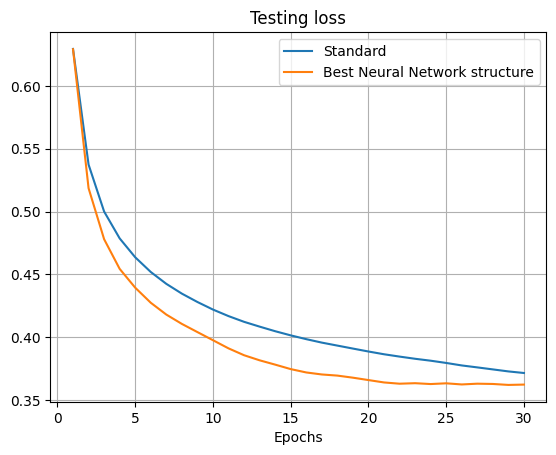

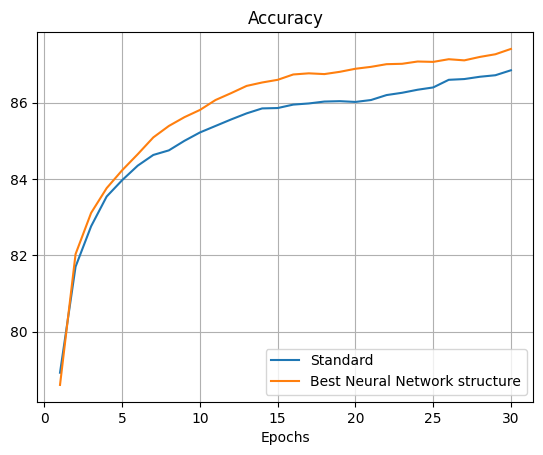

In [121]:
plot.plot_2_histories(
    std_test_loss_history, tun_test_loss_history, 'Testing loss', 'Standard', 'Best Neural Network structure')

plot.plot_2_histories(
    std_accuracy_history, tun_accuracy_history, 'Accuracy', 'Standard', 'Best Neural Network structure')